# DIT5411 三個 CNN 模型比較

同一份 notebook 依次展示 **A2、B、C** 嘅模型架構、訓練曲線、test 結果，最後放埋一張比較表同圖。唔使轉 MODE 或開另一份 notebook。

| 段落 | 模型 | 操作 |
|---|---|---|
| A | A2：Conv32/64/128 → Dense128 | **只載入現有最佳模型，唔再訓練** |
| B | Conv16/32 → Dense64 | 訓練至 3 epochs，保存及展示結果 |
| C | Conv8 → Dense16 | 訓練至 3 epochs，保存及展示結果 |

由上至下「全部執行」即可。B/C 已有完整三輪 checkpoint 就重用；未完成則接續到三輪。新模型各自使用獨立資料夾，A2 權重唔會改動。

共同設定：**48×48 灰階、batch1024、13,065 個輸出、同一份原圖分割同 augmentation**。
43 個少樣本類別（1,247 張）仍 pending；fit／validation／test 目前覆蓋 13,022 類。

Accuracy 係第一個答案答啱嘅比例；Top-5 accuracy 係最高五個答案有冇包含正確答案。B/C 嘅準確率按真實結果記錄，唔預填中／低百分比。


## 1 共用設定

A2 使用你之前成功訓練嘅資料夾。B/C 名稱留空時，會自動找最新有 checkpoint 嘅同類 run；冇就建立新 run。
如果要指定某次 B/C 實驗，可以填入 `B_RUN_NAME`／`C_RUN_NAME`，唔需要再用 MODE。


In [1]:
import csv
import hashlib
import json
import math
import os
import re
import shutil
import zipfile
from collections import Counter
from datetime import datetime
from pathlib import Path, PurePosixPath
from zoneinfo import ZoneInfo

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from IPython.display import display
from tqdm.auto import tqdm

IMG_SIZE = 48
BATCH_SIZE = 1024
NUM_CLASSES = 13065
SEED = 42
VIEWS_PER_IMAGE = 6
LEARNING_RATE = 0.0003
TARGET_EPOCHS = 3

A2_RUN_NAME = "model_a2_48_20261120_181930"
B_RUN_NAME = ""  # 留空：自動找最新已有 B；冇就建立。
C_RUN_NAME = ""  # 留空：自動找最新已有 C；冇就建立。
TRAIN_B = True
TRAIN_C = True
SHOW_PREVIEW = False

PROJECT_DIR = Path("/content/drive/MyDrive/DIT5411_Character_Recognition")
PARTS_DIR = PROJECT_DIR / "dataset_parts"
ZIP_PATH = Path("/content/all_data.zip")
EXTRACT_DIR = Path("/content/dataset")
DATA_ROOT = EXTRACT_DIR / "cleaned_data"
A2_RUN_DIR = PROJECT_DIR / A2_RUN_NAME

EXPECTED_ROWS = {
    "manifest.csv": 684677, "train.csv": 520880,
    "fit.csv": 468792, "validation.csv": 52088,
    "test.csv": 162550, "short_pending.csv": 1247,
}
MODEL_VARIANTS = {
    "b": {"filters": [16, 32], "hidden": 64, "parameters": 1149001},
    "c": {"filters": [8], "hidden": 16, "parameters": 295929},
}
assert TARGET_EPOCHS > 0
results = {}
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))
print(f"Input: {IMG_SIZE}×{IMG_SIZE}×1 | batch: {BATCH_SIZE}")


TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Input: 48×48×1 | batch: 1024


## 2 連接 Drive 同恢復資料

載入 Drive CSV，沿用固定 mapping 同原有分割。圖片喺 `/content` 遺失時先從 12 個分卷恢復；檔名內嘅反斜線按原本 Colab/Linux 檔名保留。


In [2]:
from google.colab import drive
drive.mount("/content/drive")
if not PROJECT_DIR.is_dir():
    raise FileNotFoundError(f"請確認 Drive 帳戶同位置：{PROJECT_DIR}")
if not (A2_RUN_DIR / "best.keras").is_file():
    raise FileNotFoundError(f"搵唔到原本 A2：{A2_RUN_DIR / 'best.keras'}")
print("A2 checkpoint:", A2_RUN_DIR / "best.keras")


Mounted at /content/drive
A2 checkpoint: /content/drive/MyDrive/DIT5411_Character_Recognition/model_a2_48_20261120_181930/best.keras


In [3]:
def ensure_archive():
    parts = [PARTS_DIR / f"all_data.zip.{i:03d}" for i in range(1, 13)]
    missing = [p.name for p in parts if not p.is_file()]
    if missing:
        raise FileNotFoundError(f"缺少分卷：{missing}")

    total_bytes = sum(p.stat().st_size for p in parts)
    archive_ready = (
        ZIP_PATH.is_file()
        and ZIP_PATH.stat().st_size == total_bytes
        and zipfile.is_zipfile(ZIP_PATH)
    )
    if not archive_ready:
        if shutil.disk_usage("/content").free < total_bytes + 4 * 1024**3:
            raise RuntimeError("合併及解壓前需要額外約 ZIP 大小加 4 GiB 空間。")
        temporary = ZIP_PATH.with_suffix(".zip.partial")
        with temporary.open("wb") as output:
            for part in tqdm(parts, desc="合併分卷", unit="part"):
                with part.open("rb") as source:
                    shutil.copyfileobj(source, output, length=8 * 1024 * 1024)
        if not zipfile.is_zipfile(temporary):
            raise RuntimeError("合併後未能讀取 ZIP，請檢查分卷。")
        temporary.replace(ZIP_PATH)
    return ZIP_PATH


def restore_images(required_paths=None):
    archive_path = ensure_archive()
    if shutil.disk_usage("/content").free < 4 * 1024**3:
        raise RuntimeError("解壓前請保留至少 4 GiB 可用空間。")
    EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
    wanted = None
    if required_paths is not None:
        wanted = set()
        for path in required_paths:
            absolute = Path(path)
            try:
                relative = absolute.relative_to(EXTRACT_DIR)
            except ValueError as error:
                raise ValueError(f"CSV 路徑不在資料根目錄內：{path}") from error
            wanted.add(PurePosixPath(*relative.parts).as_posix())
    extracted = set()
    with zipfile.ZipFile(archive_path) as archive:
        for info in tqdm(archive.infolist(), desc="恢復圖片", unit="file"):
            member = PurePosixPath(info.filename)
            if (member.is_absolute() or ".." in member.parts
                    or not member.parts or member.parts[0] != "cleaned_data"):
                raise ValueError(f"非預期 ZIP 路徑：{info.filename}")
            # 反斜線可以係合法檔名字符；ZIP 嘅真正路徑分隔符係 `/`。
            if wanted is not None and info.filename not in wanted:
                continue
            archive.extract(info, EXTRACT_DIR)
            if wanted is not None and not info.is_dir():
                extracted.add(info.filename)
    if wanted is not None:
        missing = wanted - extracted
        if missing:
            raise FileNotFoundError(
                f"ZIP 入面搵唔到 {len(missing)} 張所需圖片，例如：{next(iter(missing))}"
            )


def ensure_images(frame):
    image_paths = frame["path"].tolist()
    missing_count = sum(not os.path.isfile(p) for p in image_paths)
    if missing_count:
        print(f"本地欠缺 {missing_count:,} 張所需圖片，從 Drive 分卷恢復。")
        restore_images(image_paths)
        missing_count = sum(not os.path.isfile(p) for p in image_paths)
        if missing_count:
            raise FileNotFoundError(
                f"恢復後仍欠缺 {missing_count} 張圖片，請核對 CSV 路徑。"
            )
    else:
        print(f"所需圖片齊全：{len(image_paths):,} 張，跳過解壓。")


def save_csv(frame, filename):
    # 先寫入本地，再一次複製到 Drive。
    local_path = Path("/content") / filename
    frame.to_csv(local_path, index=False)
    shutil.copy2(local_path, PROJECT_DIR / filename)


def read_csv(filename):
    return pd.read_csv(PROJECT_DIR / filename, dtype={"class_id": str})


In [4]:
def build_manifest():
    grouped = {}
    pattern = re.compile(r"_(\d+)\.png$", re.IGNORECASE)
    with zipfile.ZipFile(ensure_archive()) as archive:
        for info in archive.infolist():
            if info.is_dir():
                continue
            member = PurePosixPath(info.filename)
            if (len(member.parts) != 3 or member.parts[0] != "cleaned_data"
                    or not member.parts[1].isdigit()):
                raise ValueError(f"非預期資料路徑：{info.filename}")
            match = pattern.search(member.name)
            if not match:
                raise ValueError(f"未能解析圖片編號：{info.filename}")
            grouped.setdefault(member.parts[1], []).append(
                (int(match.group(1)), member.name, str(EXTRACT_DIR / info.filename))
            )

    mapping = {cid: i for i, cid in enumerate(sorted(grouped, key=int))}
    records = []
    for cid in sorted(grouped, key=int):
        samples = sorted(grouped[cid])
        numbers = [item[0] for item in samples]
        if len(numbers) != len(set(numbers)):
            raise ValueError(f"Class {cid} 有重複樣本編號。")
        count = len(samples)
        for rank, (number, _, path) in enumerate(samples):
            status = "short_unresolved" if count < 40 else (
                "candidate_train" if rank < 40 else "candidate_test"
            )
            records.append((path, cid, mapping[cid], number, rank, count, status))
    return pd.DataFrame(records, columns=[
        "path", "class_id", "label_index", "sample_number", "rank",
        "class_count", "split_status"
    ])


manifest_file = PROJECT_DIR / "manifest.csv"
if manifest_file.is_file():
    manifest_df = read_csv("manifest.csv")
else:
    manifest_df = build_manifest()

required_columns = {
    "path", "class_id", "label_index", "sample_number", "rank",
    "class_count", "split_status"
}
assert required_columns.issubset(manifest_df.columns)
assert len(manifest_df) == EXPECTED_ROWS["manifest.csv"]
assert not manifest_df["path"].duplicated().any()
assert not manifest_df[["class_id", "sample_number"]].duplicated().any()
assert manifest_df["class_id"].str.isdigit().all()

class_ids = sorted(manifest_df["class_id"].unique(), key=int)
class_to_index = {cid: i for i, cid in enumerate(class_ids)}
assert len(class_ids) == NUM_CLASSES
assert manifest_df["label_index"].eq(
    manifest_df["class_id"].map(class_to_index)
).all()
assert manifest_df["class_count"].eq(
    manifest_df.groupby("class_id")["path"].transform("size")
).all()

mapping_df = pd.DataFrame({
    "class_id": class_ids, "label_index": range(NUM_CLASSES)
})
if (PROJECT_DIR / "class_mapping.csv").is_file():
    saved_mapping = read_csv("class_mapping.csv").sort_values("label_index")
    pd.testing.assert_frame_equal(
        saved_mapping.reset_index(drop=True), mapping_df, check_dtype=False
    )
else:
    save_csv(mapping_df, "class_mapping.csv")
if not manifest_file.is_file():
    save_csv(manifest_df, "manifest.csv")

print(f"Manifest：{len(manifest_df):,} 張 | {len(class_ids):,} 類")
print(manifest_df["split_status"].value_counts().to_string())


Manifest：684,677 張 | 13,065 類
split_status
candidate_train     520880
candidate_test      162550
short_unresolved      1247


In [5]:
pool_expected = manifest_df.loc[
    manifest_df["split_status"].eq("candidate_train")
].copy()
test_expected = manifest_df.loc[
    manifest_df["split_status"].eq("candidate_test")
].copy()
pending_expected = manifest_df.loc[
    manifest_df["split_status"].eq("short_unresolved")
].copy()

frames = {}
for filename, expected in [
    ("train.csv", pool_expected),
    ("test.csv", test_expected),
    ("short_pending.csv", pending_expected),
]:
    frame = read_csv(filename) if (PROJECT_DIR / filename).is_file() else expected
    assert len(frame) == EXPECTED_ROWS[filename]
    assert not frame["path"].duplicated().any()
    pd.testing.assert_frame_equal(
        frame.sort_values("path").reset_index(drop=True),
        expected.sort_values("path").reset_index(drop=True),
        check_dtype=False
    )
    if not (PROJECT_DIR / filename).is_file():
        save_csv(frame, filename)
    frames[filename] = frame

pool_df = frames["train.csv"]
test_df = frames["test.csv"]
pending_df = frames["short_pending.csv"]

fit_exists = (PROJECT_DIR / "fit.csv").is_file()
val_exists = (PROJECT_DIR / "validation.csv").is_file()
if fit_exists != val_exists:
    raise RuntimeError("fit.csv 同 validation.csv 必須一齊存在，請先恢復缺少嗰份。")
if fit_exists:
    fit_df, val_df = read_csv("fit.csv"), read_csv("validation.csv")
else:
    val_df = pool_df.groupby("label_index", group_keys=False).sample(
        n=4, random_state=SEED
    )
    fit_df = pool_df.drop(val_df.index)
    save_csv(fit_df, "fit.csv")
    save_csv(val_df, "validation.csv")

for frame, filename, per_class in [
    (fit_df, "fit.csv", 36), (val_df, "validation.csv", 4)
]:
    assert len(frame) == EXPECTED_ROWS[filename]
    assert not frame["path"].duplicated().any()
    assert frame.groupby("label_index").size().eq(per_class).all()
    # 檢查每個 path 嘅標籤都同固定 manifest 一致。
    canonical = manifest_df.set_index("path")["label_index"]
    assert frame["label_index"].eq(frame["path"].map(canonical)).all()

fit_paths, val_paths = set(fit_df["path"]), set(val_df["path"])
assert fit_paths.isdisjoint(val_paths)
assert fit_paths | val_paths == set(pool_df["path"])
assert (fit_paths | val_paths).isdisjoint(set(test_df["path"]))
assert pending_df["label_index"].nunique() == 43
assert set(pending_df["label_index"]).isdisjoint(set(pool_df["label_index"]))

for name, frame in [("Fit", fit_df), ("Validation", val_df),
                    ("Test", test_df), ("Pending", pending_df)]:
    print(f"{name}: {len(frame):,} 張，{frame['label_index'].nunique():,} 類")


Fit: 468,792 張，13,022 類
Validation: 52,088 張，13,022 類
Test: 162,550 張，13,022 類
Pending: 1,247 張，43 類


## 3 共用圖片處理同 augmentation

每正常類別 40 張原圖為 training pool，固定留 4 張 validation，36 張 fit；第41張起 test。Fit 每張圖產生 6 個隨機版本，每類216個 views。Validation／test 唔做 augmentation。
先將原圖分開，再增強，避免同一原圖嘅變體同時喺 training 同 validation。


In [6]:
def load_image(path, label):
    image = tf.io.decode_png(tf.io.read_file(path), channels=1)
    image = tf.image.convert_image_dtype(image, tf.float32)
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE], antialias=True)
    return tf.clip_by_value(image, 0.0, 1.0), label


def path_dataset(frame):
    return tf.data.Dataset.from_tensor_slices((
        tf.constant(frame["path"].tolist()),
        tf.constant(frame["label_index"].tolist(), dtype=tf.int32)
    ))


def make_eval_dataset(frame):
    return (path_dataset(frame)
            .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
            .batch(BATCH_SIZE).prefetch(1))


def make_augmentation():
    if not hasattr(tf.keras.layers, "RandomShear"):
        raise RuntimeError("需要支援 RandomShear 嘅 Keras；原執行版本為 TensorFlow 2.21.0。")
    return tf.keras.Sequential([
        tf.keras.layers.RandomRotation(
            8 / 360, fill_mode="constant", fill_value=1.0, seed=SEED),
        tf.keras.layers.RandomShear(
            x_factor=0.08, y_factor=0.0,
            fill_mode="constant", fill_value=1.0, seed=SEED + 1),
        tf.keras.layers.RandomZoom(
            height_factor=(-0.08, 0.08), width_factor=None,
            fill_mode="constant", fill_value=1.0, seed=SEED + 2),
    ], name="training_augmentation")


def make_train_dataset(frame):
    augmentation = make_augmentation()

    def make_views(image, label):
        return tf.data.Dataset.from_tensors((image, label)).repeat(VIEWS_PER_IMAGE)

    def augment_batch(images, labels):
        images = augmentation(images, training=True)
        return tf.clip_by_value(images, 0.0, 1.0), labels

    return (path_dataset(frame)
            .shuffle(len(frame), seed=SEED)
            .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
            .flat_map(make_views)
            .shuffle(2048, seed=SEED + 1)
            .apply(tf.data.experimental.assert_cardinality(
                len(frame) * VIEWS_PER_IMAGE))
            .batch(BATCH_SIZE)
            .map(augment_batch)
            .prefetch(1))


print("Training views / epoch:", len(fit_df) * VIEWS_PER_IMAGE)
print("Training batches:", math.ceil(len(fit_df) * VIEWS_PER_IMAGE / BATCH_SIZE))
print("Validation batches:", math.ceil(len(val_df) / BATCH_SIZE))
print("Test batches:", math.ceil(len(test_df) / BATCH_SIZE))


Training views / epoch: 2812752
Training batches: 2747
Validation batches: 51
Test batches: 159


In [7]:
if SHOW_PREVIEW:
    examples = (fit_df.drop_duplicates("label_index")
                .sort_values("label_index"))
    positions = np.linspace(0, len(examples) - 1, 4, dtype=int)
    examples = examples.iloc[positions]
    ensure_images(examples)
    originals = tf.stack([
        load_image(row.path, row.label_index)[0]
        for row in examples.itertuples()
    ])
    preview_aug = make_augmentation()
    views = [originals] + [layer(originals, training=True)
                           for layer in preview_aug.layers]
    fig, axes = plt.subplots(4, 4, figsize=(10, 10))
    for row in range(4):
        for col, title in enumerate(["Original", "Rotation", "Shear", "Zoom"]):
            axes[row, col].imshow(views[col][row, :, :, 0], cmap="gray", vmin=0, vmax=1)
            axes[row, col].axis("off")
            if row == 0:
                axes[row, col].set_title(title)
        axes[row, 0].set_title(f"Class {examples.iloc[row]['class_id']}")
    plt.tight_layout()
    plt.show()
else:
    print("跳過預覽；需要時設定 SHOW_PREVIEW = True。")


跳過預覽；需要時設定 SHOW_PREVIEW = True。


## 4 共用記錄與展示工具

各段保留自己嘅模型變數、run 同結果。Checkpoint 同已保存 test JSON 嘅 SHA256 一致就重用該 test 成績；否則重新 evaluate。
訓練 checkpoint 每輪完成後保存；續訓由最近完成嘅 epoch 開始，唔保證重播中斷前每個隨機 batch。


In [8]:
def evaluation_metrics():
    return [
        tf.keras.metrics.SparseCategoricalAccuracy(name="accuracy"),
        tf.keras.metrics.SparseTopKCategoricalAccuracy(k=5, name="top5_accuracy"),
    ]


def load_for_evaluation(run_dir):
    model = tf.keras.models.load_model(str(run_dir / "best.keras"), compile=False)
    assert model.input_shape == (None, IMG_SIZE, IMG_SIZE, 1)
    assert model.output_shape == (None, NUM_CLASSES)
    model.compile(loss=tf.keras.losses.SparseCategoricalCrossentropy(),
                  metrics=evaluation_metrics())
    return model


def compile_new_model(model):
    model.compile(
        optimizer=tf.keras.optimizers.Adam(LEARNING_RATE),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(),
        metrics=evaluation_metrics()
    )
    return model


def show_history(run_dir, title):
    log_path = run_dir / "training_log.csv"
    if not log_path.is_file():
        print("未有訓練紀錄：", run_dir)
        return pd.DataFrame()
    log = pd.read_csv(log_path)
    display(log.assign(epoch=log["epoch"] + 1))
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    for key, ax in zip(["accuracy", "loss"], axes):
        ax.plot(log["epoch"] + 1, log[key], "o-", label="Training")
        ax.plot(log["epoch"] + 1, log[f"val_{key}"], "o-", label="Validation")
        ax.set_title(f"{title} | {key}")
        ax.set_xlabel("Epoch")
        ax.legend()
    plt.tight_layout()
    plt.show()
    return log


def evaluate_or_reuse(model, run_dir, title):
    checkpoint = run_dir / "best.keras"
    sha256 = hashlib.sha256(checkpoint.read_bytes()).hexdigest()
    for path in sorted(run_dir.glob("test_results_*.json"), reverse=True):
        saved = json.loads(path.read_text(encoding="utf-8"))
        if (saved.get("checkpoint_sha256") == sha256
                and saved.get("test_images") == len(test_df)
                and saved.get("test_classes") == int(test_df["label_index"].nunique())
                and saved.get("image_size") == IMG_SIZE
                and {"accuracy", "top5_accuracy", "loss"}.issubset(saved.get("metrics", {}))):
            metrics = saved["metrics"]
            print("重用相同 checkpoint 嘅 test 結果：", path.name)
            break
    else:
        ensure_images(test_df)
        metrics = model.evaluate(make_eval_dataset(test_df), return_dict=True, verbose=1)
        metrics = {key: float(value) for key, value in metrics.items()}
        timestamp = datetime.now(ZoneInfo("Asia/Hong_Kong")).strftime("%Y%m%d_%H%M%S")
        record = {
            "evaluated_at_hong_kong": timestamp,
            "checkpoint": str(checkpoint), "checkpoint_sha256": sha256,
            "test_images": len(test_df),
            "test_classes": int(test_df["label_index"].nunique()),
            "excluded_pending_classes": 43, "image_size": IMG_SIZE,
            "batch_size": BATCH_SIZE, "metrics": metrics,
        }
        (run_dir / f"test_results_{timestamp}.json").write_text(
            json.dumps(record, indent=2), encoding="utf-8")
    print(f"{title} Test accuracy: {metrics['accuracy']:.2%}")
    print(f"{title} Test Top-5 accuracy: {metrics['top5_accuracy']:.2%}")
    print(f"{title} Test loss: {metrics['loss']:.4f}")
    return dict(metrics)


def select_or_create_run(variant, requested_name):
    if variant not in MODEL_VARIANTS:
        raise ValueError("只可為 B／C 建立或接續 run。")
    pattern = rf"model_{variant}_48_\d{{8}}_\d{{6}}"
    if requested_name:
        if not re.fullmatch(pattern, requested_name):
            raise ValueError(f"非預期 {variant.upper()} run 名稱：{requested_name}")
        run_dir = PROJECT_DIR / requested_name
        if not run_dir.is_dir():
            raise FileNotFoundError(run_dir)
    else:
        candidates = [p for p in sorted(PROJECT_DIR.glob(f"model_{variant}_48_*"))
                      if re.fullmatch(pattern, p.name)
                      and (p / "training_log.csv").is_file()
                      and (p / "latest.keras").is_file()
                      and (p / "best.keras").is_file()]
        if candidates:
            run_dir = candidates[-1]
        else:
            stamp = datetime.now(ZoneInfo("Asia/Hong_Kong")).strftime("%Y%m%d_%H%M%S")
            run_dir = PROJECT_DIR / f"model_{variant}_48_{stamp}"
            run_dir.mkdir(exist_ok=False)
    assert run_dir != A2_RUN_DIR
    config_path = run_dir / "config.json"
    if config_path.is_file():
        config = json.loads(config_path.read_text(encoding="utf-8"))
        if (config.get("model", "").lower() != variant
                or config.get("image_size") != IMG_SIZE
                or config.get("num_outputs") != NUM_CLASSES
                or config.get("parameters") != MODEL_VARIANTS[variant]["parameters"]):
            raise ValueError(f"Run 設定唔符合 {variant.upper()}：{run_dir}")
    return run_dir


def prepare_model(variant, run_dir, builder):
    assert variant in MODEL_VARIANTS and run_dir != A2_RUN_DIR
    saved_files = [run_dir / name for name in
                   ["training_log.csv", "latest.keras", "best.keras"]]
    if any(p.is_file() for p in saved_files):
        if not all(p.is_file() for p in saved_files):
            raise RuntimeError(f"Run 紀錄或 checkpoint 唔齊全，請核對：{run_dir}")
        model = tf.keras.models.load_model(str(run_dir / "latest.keras"))
        assert model.name == f"model_{variant}"
    else:
        tf.keras.utils.set_random_seed(SEED)
        model = builder()
    assert model.count_params() == MODEL_VARIANTS[variant]["parameters"]
    assert model.input_shape == (None, IMG_SIZE, IMG_SIZE, 1)
    assert model.output_shape == (None, NUM_CLASSES)
    return model


def train_to_target(model, run_dir, variant, enabled):
    # A2 永遠唔可以進入呢個訓練函數。
    if variant not in MODEL_VARIANTS or run_dir == A2_RUN_DIR:
        raise ValueError("A2 保留 checkpoint，唔再訓練。")
    assert model.name == f"model_{variant}"
    log_path = run_dir / "training_log.csv"
    if log_path.is_file():
        log = pd.read_csv(log_path)
        initial_epoch = int(log["epoch"].max()) + 1
        historical_best = float(log["val_accuracy"].max())
    else:
        initial_epoch, historical_best = 0, None
    if initial_epoch >= TARGET_EPOCHS:
        print(f"{variant.upper()} 已完成 {initial_epoch} epochs；跳過訓練。")
        return model
    if not enabled:
        print(f"{variant.upper()} 未啟用訓練，已有 {initial_epoch} epochs。")
        return model
    if not tf.config.list_physical_devices("GPU"):
        raise RuntimeError("請喺 Colab Runtime 啟用 GPU。")
    if initial_epoch > 0:
        # 即使只重跑訓練格，亦由 latest checkpoint 同 optimizer 接續。
        model = tf.keras.models.load_model(str(run_dir / "latest.keras"))
        assert model.name == f"model_{variant}"

    required = pd.concat([fit_df, val_df], ignore_index=True)
    ensure_images(required)
    train_ds = make_train_dataset(fit_df)
    val_ds = make_eval_dataset(val_df)
    config = {
        "model": variant.upper(), "parameters": model.count_params(),
        "filters": MODEL_VARIANTS[variant]["filters"],
        "hidden_units": MODEL_VARIANTS[variant]["hidden"],
        "image_size": IMG_SIZE, "batch_size": BATCH_SIZE,
        "num_outputs": NUM_CLASSES, "seed": SEED,
        "learning_rate": LEARNING_RATE, "views_per_fit_image": VIEWS_PER_IMAGE,
        "fit_images": len(fit_df), "validation_images": len(val_df),
        "pending_images": len(pending_df), "pending_classes": 43,
        "rotation_degrees": 8, "shear_x_factor": 0.08, "zoom_factor": 0.08,
        "tensorflow": tf.__version__, "keras": tf.keras.__version__,
    }
    if not (run_dir / "config.json").is_file():
        (run_dir / "config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
        shutil.copy2(PROJECT_DIR / "class_mapping.csv", run_dir / "class_mapping.csv")
    callbacks = [
        tf.keras.callbacks.ModelCheckpoint(
            str(run_dir / "best.keras"), monitor="val_accuracy", mode="max",
            save_best_only=True, initial_value_threshold=historical_best),
        tf.keras.callbacks.ModelCheckpoint(str(run_dir / "latest.keras")),
        tf.keras.callbacks.CSVLogger(str(log_path), append=(initial_epoch > 0)),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.5, patience=2, min_lr=0.00001, verbose=1),
    ]
    print(f"{variant.upper()}：由 epoch {initial_epoch + 1} 訓練至 {TARGET_EPOCHS}")
    model.fit(train_ds, validation_data=val_ds, initial_epoch=initial_epoch,
              epochs=TARGET_EPOCHS, callbacks=callbacks, verbose=1)
    return model


def make_result_row(title, model, run_dir, log, metrics):
    row = {
        "model": title, "run": run_dir.name, "parameters": model.count_params(),
        "epochs": int(log["epoch"].max()) + 1 if not log.empty else None,
        "test_top1_pct": metrics["accuracy"] * 100,
        "test_top5_pct": metrics["top5_accuracy"] * 100,
        "test_loss": metrics["loss"],
        "test_images": len(test_df),
        "test_classes": int(test_df["label_index"].nunique()),
    }
    if not log.empty:
        best = log.loc[log["val_accuracy"].idxmax()]
        row["best_val_top1_pct"] = float(best["val_accuracy"]) * 100
        row["val_top5_at_best_pct"] = float(best["val_top5_accuracy"]) * 100
    return row


## 模型 A — A2 保留模型

呢段只 load 已保存嘅 `best.keras`，展示架構、歷史曲線同 test 結果，**唔會呼叫 fit**。
原 notebook 已記錄三輪 validation Top-1：49.26% → 71.72% → 78.15%；第三輪 validation Top-5 95.25%。以下表格同曲線會從 Drive 實際讀取。


In [9]:
model_a2 = load_for_evaluation(A2_RUN_DIR)
print("A2 run:", A2_RUN_DIR)
model_a2.summary()


A2 run: /content/drive/MyDrive/DIT5411_Character_Recognition/model_a2_48_20261120_181930


Model: "model_a2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_5 (LeakyReLU)       │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_6 (LeakyReLU)       │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_7 (LeakyReLU)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 13065)          │     1,685,385 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,368,009 (9.03 MB)

 Trainable params: 2,368,009 (9.03 MB)

 Non-trainable params: 0 (0.00 B)

,epoch,accuracy,loss,top5_accuracy,val_accuracy,val_loss,val_top5_accuracy
0,1,0.116869,6.120598,0.245420,0.492609,2.086205,0.789145
1,2,0.531300,1.954203,0.800898,0.717171,1.041147,0.929523
2,3,0.692110,1.173823,0.907774,0.781485,0.789068,0.952523


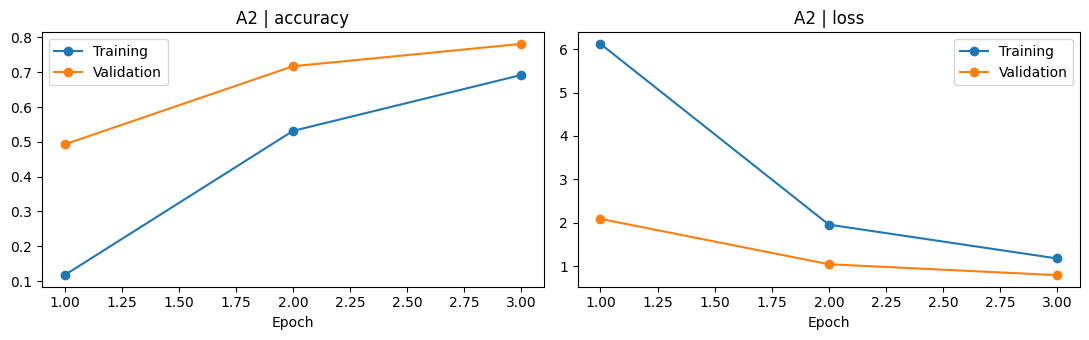

重用相同 checkpoint 嘅 test 結果： test_results_20261121_004401.json
A2 Test accuracy: 74.58%
A2 Test Top-5 accuracy: 93.98%
A2 Test loss: 0.9485


In [10]:
history_a2 = show_history(A2_RUN_DIR, "A2")
metrics_a2 = evaluate_or_reuse(model_a2, A2_RUN_DIR, "A2")
results["A2"] = make_result_row("A2", model_a2, A2_RUN_DIR, history_a2, metrics_a2)


## 模型 B — 中等容量 CNN

兩組卷積：Conv16 → Pool → Conv32 → Pool → Dense64 → 13,065 類。
參數 1,149,001。先訓練到三輪，同 A2 使用相同資料量同指標；準確率按結果記錄。


In [11]:
def build_model_b():
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(IMG_SIZE, IMG_SIZE, 1)),
        tf.keras.layers.Rescaling(-1.0, offset=1.0),

        tf.keras.layers.Conv2D(16, 3, padding="same", kernel_initializer="he_normal"),
        tf.keras.layers.LeakyReLU(negative_slope=0.1),
        tf.keras.layers.MaxPooling2D(),

        tf.keras.layers.Conv2D(32, 3, padding="same", kernel_initializer="he_normal"),
        tf.keras.layers.LeakyReLU(negative_slope=0.1),
        tf.keras.layers.MaxPooling2D(),

        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(64, kernel_initializer="he_normal"),
        tf.keras.layers.LeakyReLU(negative_slope=0.1),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(NUM_CLASSES, activation="softmax", dtype="float32"),
    ], name="model_b")
    return compile_new_model(model)


B_RUN_DIR = select_or_create_run("b", B_RUN_NAME)
model_b = prepare_model("b", B_RUN_DIR, build_model_b)
print("B run:", B_RUN_DIR)
model_b.summary()


B run: /content/drive/MyDrive/DIT5411_Character_Recognition/model_b_48_20261121_012238


Model: "model_b"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 48, 48, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 48, 48, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       294,976 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 13065)          │       849,225 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,149,001 (4.38 MB)

 Trainable params: 1,149,001 (4.38 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
# 呢格只訓練 B；已完成三輪就跳過。
model_b = train_to_target(model_b, B_RUN_DIR, "b", TRAIN_B)


本地欠缺 520,880 張所需圖片，從 Drive 分卷恢復。


合併分卷:   0%|          | 0/12 [00:00<?, ?part/s]

恢復圖片:   0%|          | 0/697743 [00:00<?, ?file/s]

B：由 epoch 1 訓練至 3
Epoch 1/3
2747/2747 ━━━━━━━━━━━━━━━━━━━━ 1340s 484ms/step - accuracy: 0.0219 - loss: 7.6498 - top5_accuracy: 0.0644 - val_accuracy: 0.1324 - val_loss: 4.8512 - val_top5_accuracy: 0.3242 - learning_rate: 3.0000e-04
Epoch 2/3
2747/2747 ━━━━━━━━━━━━━━━━━━━━ 1303s 474ms/step - accuracy: 0.1627 - loss: 4.6124 - top5_accuracy: 0.3652 - val_accuracy: 0.3942 - val_loss: 2.7630 - val_top5_accuracy: 0.6862 - learning_rate: 3.0000e-04
Epoch 3/3
2747/2747 ━━━━━━━━━━━━━━━━━━━━ 1300s 473ms/step - accuracy: 0.2884 - loss: 3.5228 - top5_accuracy: 0.5489 - val_accuracy: 0.5174 - val_loss: 2.0965 - val_top5_accuracy: 0.7930 - learning_rate: 3.0000e-04


,epoch,accuracy,loss,top5_accuracy,val_accuracy,val_loss,val_top5_accuracy
0,1,0.021890,7.649797,0.064387,0.132372,4.851222,0.324201
1,2,0.162730,4.612443,0.365177,0.394179,2.763025,0.686223
2,3,0.288358,3.522798,0.548915,0.517355,2.096509,0.792966


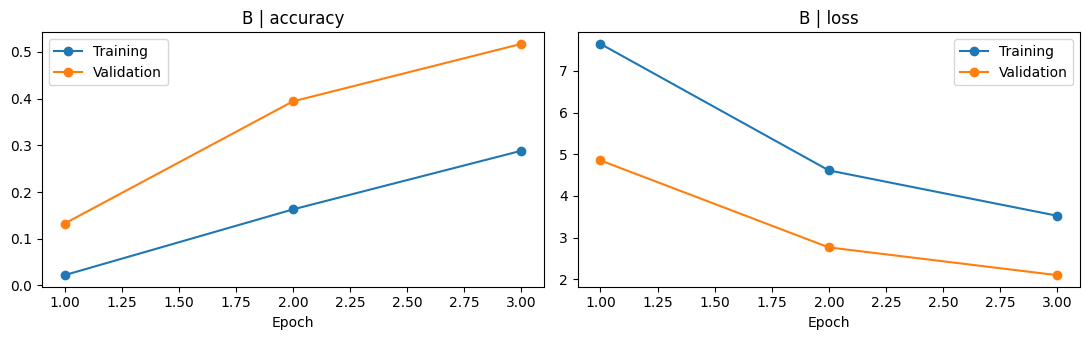

本地欠缺 162,550 張所需圖片，從 Drive 分卷恢復。


恢復圖片:   0%|          | 0/697743 [00:00<?, ?file/s]

159/159 ━━━━━━━━━━━━━━━━━━━━ 220s 1s/step - accuracy: 0.4844 - loss: 2.2836 - top5_accuracy: 0.7601
B Test accuracy: 48.44%
B Test Top-5 accuracy: 76.01%
B Test loss: 2.2836


In [13]:
history_b = show_history(B_RUN_DIR, "B")
if (B_RUN_DIR / "best.keras").is_file():
    eval_model_b = load_for_evaluation(B_RUN_DIR)
    metrics_b = evaluate_or_reuse(eval_model_b, B_RUN_DIR, "B")
    results["B"] = make_result_row("B", eval_model_b, B_RUN_DIR, history_b, metrics_b)
else:
    print("B 未有 checkpoint；啟用 TRAIN_B 再執行 B 訓練格。")


## 模型 C — 低容量 CNN

一組卷積：Conv8 → Pool → Dense16 → 13,065 類。
參數 295,929。訓練到三輪後用同一 test set 評估。低容量唔保證一定較低準確率，按實測結果比較。


In [14]:
def build_model_c():
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(IMG_SIZE, IMG_SIZE, 1)),
        tf.keras.layers.Rescaling(-1.0, offset=1.0),

        tf.keras.layers.Conv2D(8, 3, padding="same", kernel_initializer="he_normal"),
        tf.keras.layers.LeakyReLU(negative_slope=0.1),
        tf.keras.layers.MaxPooling2D(),

        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(16, kernel_initializer="he_normal"),
        tf.keras.layers.LeakyReLU(negative_slope=0.1),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(NUM_CLASSES, activation="softmax", dtype="float32"),
    ], name="model_c")
    return compile_new_model(model)


C_RUN_DIR = select_or_create_run("c", C_RUN_NAME)
model_c = prepare_model("c", C_RUN_DIR, build_model_c)
print("C run:", C_RUN_DIR)
model_c.summary()


C run: /content/drive/MyDrive/DIT5411_Character_Recognition/model_c_48_20261121_023518


Model: "model_c"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 48, 48, 8)      │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 48, 48, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 24, 24, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │        73,744 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 13065)          │       222,105 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 295,929 (1.13 MB)

 Trainable params: 295,929 (1.13 MB)

 Non-trainable params: 0 (0.00 B)

In [15]:
# 呢格只訓練 C；已完成三輪就跳過。
model_c = train_to_target(model_c, C_RUN_DIR, "c", TRAIN_C)


所需圖片齊全：520,880 張，跳過解壓。
C：由 epoch 1 訓練至 3
Epoch 1/3
2747/2747 ━━━━━━━━━━━━━━━━━━━━ 1293s 468ms/step - accuracy: 0.0014 - loss: 8.8014 - top5_accuracy: 0.0057 - val_accuracy: 0.0080 - val_loss: 7.6921 - val_top5_accuracy: 0.0297 - learning_rate: 3.0000e-04
Epoch 2/3
2747/2747 ━━━━━━━━━━━━━━━━━━━━ 1287s 468ms/step - accuracy: 0.0065 - loss: 7.8349 - top5_accuracy: 0.0246 - val_accuracy: 0.0211 - val_loss: 7.0059 - val_top5_accuracy: 0.0718 - learning_rate: 3.0000e-04
Epoch 3/3
2747/2747 ━━━━━━━━━━━━━━━━━━━━ 1300s 473ms/step - accuracy: 0.0109 - loss: 7.5083 - top5_accuracy: 0.0393 - val_accuracy: 0.0303 - val_loss: 6.6604 - val_top5_accuracy: 0.0995 - learning_rate: 3.0000e-04


,epoch,accuracy,loss,top5_accuracy,val_accuracy,val_loss,val_top5_accuracy
0,1,0.001375,8.801399,0.005679,0.008025,7.692090,0.029738
1,2,0.006459,7.834946,0.024594,0.021061,7.005859,0.071821
2,3,0.010857,7.508327,0.039278,0.030333,6.660405,0.099485


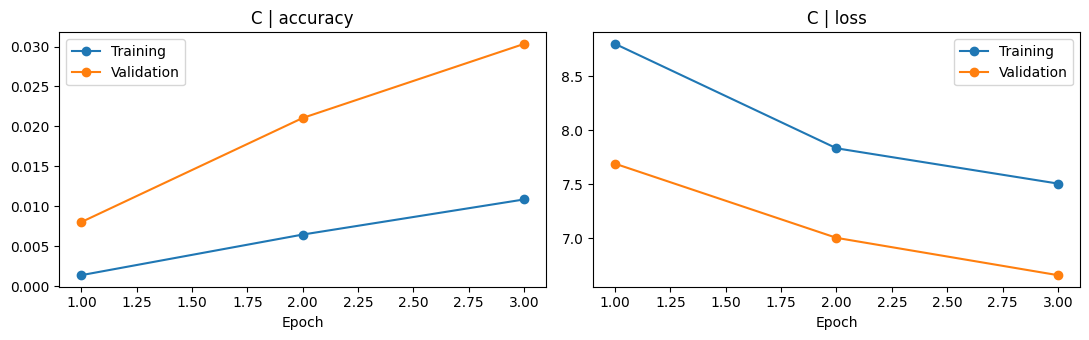

所需圖片齊全：162,550 張，跳過解壓。
159/159 ━━━━━━━━━━━━━━━━━━━━ 219s 1s/step - accuracy: 0.0303 - loss: 6.7171 - top5_accuracy: 0.0970
C Test accuracy: 3.03%
C Test Top-5 accuracy: 9.70%
C Test loss: 6.7171


In [16]:
history_c = show_history(C_RUN_DIR, "C")
if (C_RUN_DIR / "best.keras").is_file():
    eval_model_c = load_for_evaluation(C_RUN_DIR)
    metrics_c = evaluate_or_reuse(eval_model_c, C_RUN_DIR, "C")
    results["C"] = make_result_row("C", eval_model_c, C_RUN_DIR, history_c, metrics_c)
else:
    print("C 未有 checkpoint；啟用 TRAIN_C 再執行 C 訓練格。")


## 三個模型結果比較

同一頁並列 A2／B／C 嘅 Top-1、Top-5、loss 同參數數量。表格只放以上各段實際讀取或計算嘅結果；未完成模型唔會代填。
各模型 checkpoint 按 validation accuracy 選取，唔按 test 成績挑 checkpoint。


,model,run,parameters,epochs,test_top1_pct,test_top5_pct,test_loss,test_images,test_classes,best_val_top1_pct,val_top5_at_best_pct
0,A2,model_a2_48_20261120_181930,2368009,3,74.577,93.985,0.948,162550,13022,78.149,95.252
1,B,model_b_48_20261121_012238,1149001,3,48.442,76.010,2.284,162550,13022,51.736,79.297
2,C,model_c_48_20261121_023518,295929,3,3.029,9.701,6.717,162550,13022,3.033,9.949


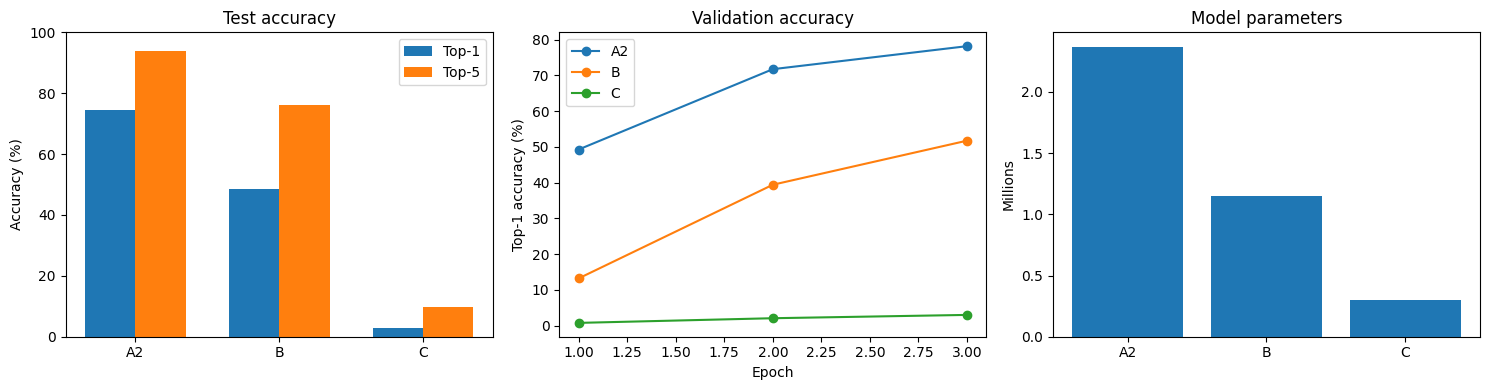

比較表： /content/drive/MyDrive/DIT5411_Character_Recognition/model_comparison.csv
比較圖： /content/drive/MyDrive/DIT5411_Character_Recognition/model_comparison.png


In [17]:
comparison = pd.DataFrame([results[key] for key in ["A2", "B", "C"] if key in results])
display(comparison.round(3))
comparison.to_csv(PROJECT_DIR / "model_comparison.csv", index=False)

if not comparison.empty:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    positions = np.arange(len(comparison))
    width = 0.35
    axes[0].bar(positions - width / 2, comparison["test_top1_pct"], width, label="Top-1")
    axes[0].bar(positions + width / 2, comparison["test_top5_pct"], width, label="Top-5")
    axes[0].set_xticks(positions, comparison["model"])
    axes[0].set_ylim(0, 100)
    axes[0].set_ylabel("Accuracy (%)")
    axes[0].set_title("Test accuracy")
    axes[0].legend()

    for title, log in [("A2", history_a2), ("B", history_b), ("C", history_c)]:
        if not log.empty:
            axes[1].plot(log["epoch"] + 1, log["val_accuracy"] * 100, "o-", label=title)
    axes[1].set_title("Validation accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Top-1 accuracy (%)")
    axes[1].legend()

    axes[2].bar(comparison["model"], comparison["parameters"] / 1_000_000)
    axes[2].set_title("Model parameters")
    axes[2].set_ylabel("Millions")
    plt.tight_layout()
    plt.show()

    figure_path = PROJECT_DIR / "model_comparison.png"
    fig.savefig(figure_path, dpi=160, bbox_inches="tight")
    print("比較表：", PROJECT_DIR / "model_comparison.csv")
    print("比較圖：", figure_path)

if set(results) != {"A2", "B", "C"}:
    print("尚未完成：", sorted({"A2", "B", "C"} - set(results)))


## 執行同提交注意

所有模型輸出會保留喺同一份 Colab notebook。完成三段後儲存 notebook，交作業前可以一次過展示三個 summary、各自曲線同最後比較。

本機整理過程只檢查語法、資料邏輯同執行分支，未喺 Colab 代跑 B/C，亦冇預填實驗分數。原 A2 checkpoint 只讀；新 test JSON 同圖表會保存到 Drive。

目前仍有43類 pending，最終報告要註明 13,022 類測試覆蓋範圍，並處理老師對少樣本類別嘅要求。資料來源：[Traditional Chinese Handwriting Dataset](https://github.com/AI-FREE-Team/Traditional-Chinese-Handwriting-Dataset)。
